In [1]:
from google.colab import drive
drive.mount('/content/drive')

import sys, os, json, shutil, importlib
sys.path.append("/content/drive/MyDrive/tcc")
from src import config

import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm

Mounted at /content/drive


In [2]:
%%writefile /content/drive/MyDrive/tcc/src/ela.py
import io
import numpy as np
from PIL import Image


def calcular_ela(img, qualidade=95):
    """Diferença absoluta entre a imagem e ela mesma recomprimida em JPEG."""
    img = img.convert("RGB")
    buf = io.BytesIO()
    img.save(buf, "JPEG", quality=qualidade, subsampling=0)
    buf.seek(0)
    with Image.open(buf) as rec:
        rec = np.asarray(rec.convert("RGB"), dtype=np.float32)
    return np.abs(np.asarray(img, dtype=np.float32) - rec)


def escalar(ela, fator):
    """Converte o ELA para uint8 com um fator fixo, igual para todas as imagens."""
    return np.clip(ela * fator, 0, 255).astype(np.uint8)


def posicoes_grade(altura, largura, tamanho, n):
    """Posições fixas, espalhadas pela imagem (usadas na validação e no teste)."""
    lado = int(np.ceil(np.sqrt(n)))
    ys = np.linspace(0, altura - tamanho, lado).astype(int)
    xs = np.linspace(0, largura - tamanho, lado).astype(int)
    return [(int(y), int(x)) for y in ys for x in xs][:n]


def posicoes_aleatorias(altura, largura, tamanho, n, rng):
    """Posições sorteadas (usadas no treino)."""
    return [
        (int(rng.integers(0, altura - tamanho + 1)), int(rng.integers(0, largura - tamanho + 1)))
        for _ in range(n)
    ]

Writing /content/drive/MyDrive/tcc/src/ela.py


In [3]:
from src import ela
importlib.reload(ela)

df = pd.read_csv(config.DATASET_CSV)
DESTINO = f"{config.ELA_DIR}/etapa1"
os.makedirs(DESTINO, exist_ok=True)
print(df["split"].value_counts())

split
treino    3500
teste      750
val        750
Name: count, dtype: int64


In [4]:
FATOR_JSON = f"{DESTINO}/fator_ela.json"

if os.path.exists(FATOR_JSON):
    FATOR = json.load(open(FATOR_JSON))["fator"]
    print("Fator já calculado:", FATOR)
else:
    base = df[(df["split"] == "treino") & (df["versao"] == "original") & (df["papel"] == "principal")]
    amostra = base.groupby("classe").sample(30, random_state=config.SEED)

    resumo = []
    for _, linha in tqdm(amostra.iterrows(), total=len(amostra), desc="Calibrando"):
        with Image.open(f"{config.DRIVE}/{linha['arquivo']}") as img:
            e = ela.calcular_ela(img, config.ELA_QUALIDADE)
        resumo.append({"classe": linha["classe"], "media": e.mean(), "p99_5": np.percentile(e, 99.5)})

    resumo = pd.DataFrame(resumo)
    print(resumo.groupby("classe")[["media", "p99_5"]].describe().round(2))

    FATOR = round(255 / float(resumo["p99_5"].median()), 2)
    json.dump({"fator": FATOR, "qualidade": config.ELA_QUALIDADE}, open(FATOR_JSON, "w"))
    print("Fator escolhido:", FATOR)

Calibrando: 100%|██████████| 60/60 [00:39<00:00,  1.50it/s]

       media                                           p99_5                   \
       count  mean   std   min   25%   50%   75%   max count  mean   std  min   
classe                                                                          
ia      30.0  1.70  0.47  0.63  1.43  1.70  1.99  2.74  30.0  7.60  2.14  3.0   
real    30.0  1.48  0.34  0.93  1.21  1.44  1.64  2.50  30.0  6.53  1.59  4.0   

                             
        25%  50%  75%   max  
classe                       
ia      6.0  7.0  9.0  12.0  
real    5.0  6.0  7.0  11.0  
Fator escolhido: 36.43


In [5]:
T = config.CROP
N = config.CROPS_TREINO

def extrair(sub, nome, aleatorio):
    arq_ela = f"{DESTINO}/{nome}_ela.npy"
    if os.path.exists(arq_ela):
        print(f"{nome}: já existe, pulando")
        return

    rng = np.random.default_rng(config.SEED)
    total = len(sub) * N
    tmp_ela = np.lib.format.open_memmap(f"/content/{nome}_ela.npy", mode="w+", dtype=np.uint8, shape=(total, T, T, 3))
    tmp_rgb = np.lib.format.open_memmap(f"/content/{nome}_rgb.npy", mode="w+", dtype=np.uint8, shape=(total, T, T, 3))

    rotulos, k = [], 0
    for _, linha in tqdm(sub.iterrows(), total=len(sub), desc=nome):
        with Image.open(f"{config.DRIVE}/{linha['arquivo']}") as img:
            img = img.convert("RGB")
            rgb = np.asarray(img)
            e = ela.escalar(ela.calcular_ela(img, config.ELA_QUALIDADE), FATOR)

        h, w = rgb.shape[:2]
        if aleatorio:
            posicoes = ela.posicoes_aleatorias(h, w, T, N, rng)
        else:
            posicoes = ela.posicoes_grade(h, w, T, N)

        for y, x in posicoes:
            tmp_ela[k] = e[y:y + T, x:x + T]
            tmp_rgb[k] = rgb[y:y + T, x:x + T]
            rotulos.append({
                "indice": k, "id": linha["id"], "classe": linha["classe"],
                "rotulo": int(linha["classe"] == "ia"),
                "aparelho_ou_gerador": linha["aparelho_ou_gerador"],
                "versao": linha["versao"], "split": linha["split"], "y": y, "x": x,
            })
            k += 1

    tmp_ela.flush(); tmp_rgb.flush()
    del tmp_ela, tmp_rgb

    shutil.copy(f"/content/{nome}_rgb.npy", f"{DESTINO}/{nome}_rgb.npy")
    shutil.copy(f"/content/{nome}_ela.npy", arq_ela)
    os.remove(f"/content/{nome}_ela.npy"); os.remove(f"/content/{nome}_rgb.npy")
    pd.DataFrame(rotulos).to_csv(f"{DESTINO}/{nome}_rotulos.csv", index=False)
    print(f"{nome}: {k} crops salvos")

In [9]:
AMOSTRA = None          # troque para None para rodar com tudo

if AMOSTRA:
    DESTINO = f"{config.ELA_DIR}/etapa1_amostra"
    os.makedirs(DESTINO, exist_ok=True)
    ids_amostra = df.groupby("split")["id"].apply(lambda s: s.drop_duplicates().head(AMOSTRA)).explode()
    dados = df[df["id"].isin(ids_amostra)]
else:
    DESTINO = f"{config.ELA_DIR}/etapa1"
    dados = df

principal = dados[dados["papel"] == "principal"]
for versao in ["original", "jpeg90"]:
    for split in ["treino", "val", "teste"]:
        sub = principal[(principal["versao"] == versao) & (principal["split"] == split)]
        extrair(sub, f"{split}_{versao}", aleatorio=(split == "treino"))

firefly = dados[(dados["papel"] == "ood") & (dados["split"] == "teste")]
extrair(firefly, "teste_firefly", aleatorio=False)

treino_original: 100%|██████████| 1400/1400 [10:35<00:00,  2.20it/s]


treino_original: 5600 crops salvos


val_original: 100%|██████████| 300/300 [02:22<00:00,  2.10it/s]


val_original: 1200 crops salvos


teste_original: 100%|██████████| 300/300 [02:21<00:00,  2.12it/s]


teste_original: 1200 crops salvos


... (4 outputs left out)

teste_jpeg90: 100%|██████████| 300/300 [01:21<00:00,  3.69it/s]


teste_jpeg90: 1200 crops salvos


teste_firefly: 100%|██████████| 150/150 [01:44<00:00,  1.43it/s]


teste_firefly: 600 crops salvos


In [10]:
for nome in sorted(f for f in os.listdir(DESTINO) if f.endswith("_ela.npy")):
    arr = np.load(f"{DESTINO}/{nome}", mmap_mode="r")
    rot = pd.read_csv(f"{DESTINO}/{nome.replace('_ela.npy', '_rotulos.csv')}")
    print(f"{nome:28s} {arr.shape}  reais={(rot.rotulo == 0).sum()}  ia={(rot.rotulo == 1).sum()}")

teste_firefly_ela.npy        (600, 256, 256, 3)  reais=0  ia=600
teste_jpeg90_ela.npy         (1200, 256, 256, 3)  reais=600  ia=600
teste_original_ela.npy       (1200, 256, 256, 3)  reais=600  ia=600
treino_jpeg90_ela.npy        (5600, 256, 256, 3)  reais=2800  ia=2800
treino_original_ela.npy      (5600, 256, 256, 3)  reais=2800  ia=2800
val_jpeg90_ela.npy           (1200, 256, 256, 3)  reais=600  ia=600
val_original_ela.npy         (1200, 256, 256, 3)  reais=600  ia=600


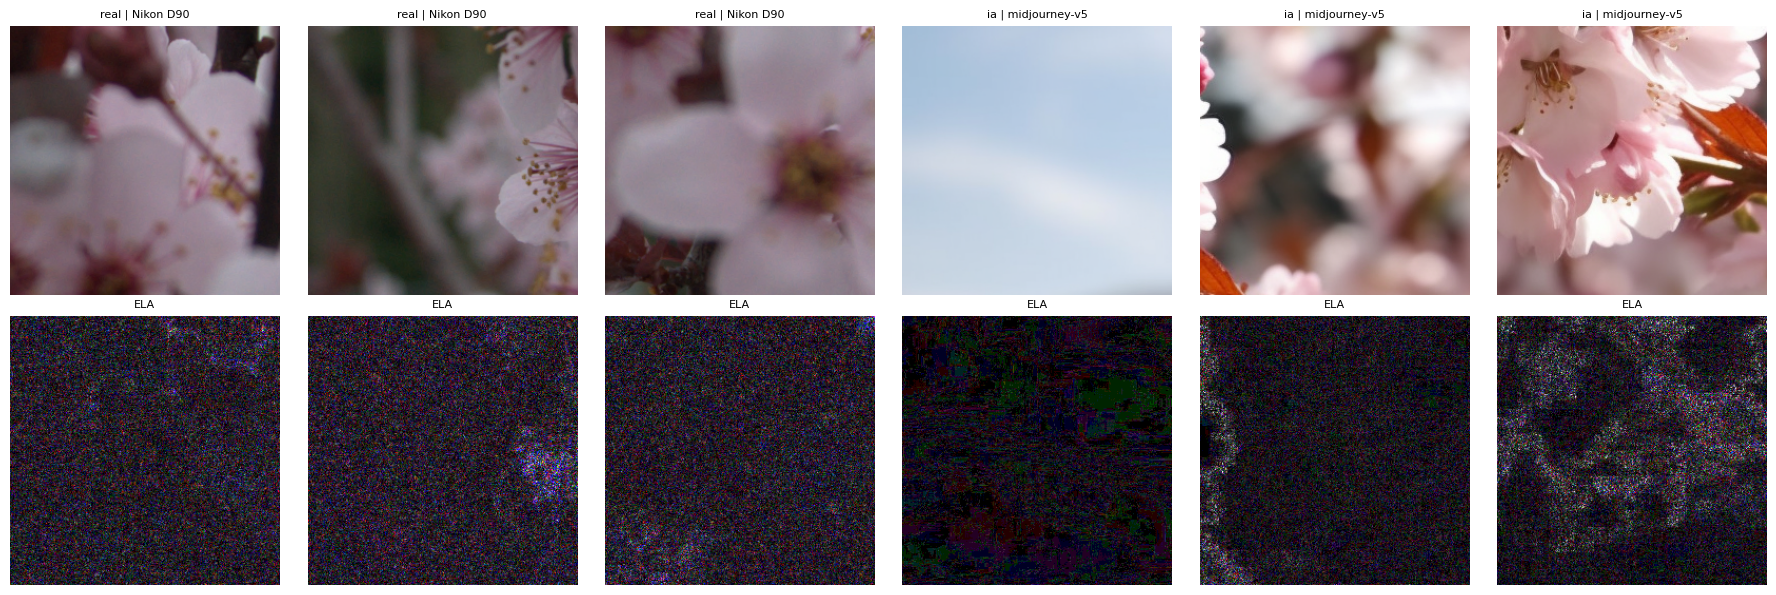

In [11]:



import matplotlib.pyplot as plt

arr_ela = np.load(f"{DESTINO}/treino_original_ela.npy", mmap_mode="r")
arr_rgb = np.load(f"{DESTINO}/treino_original_rgb.npy", mmap_mode="r")
rot = pd.read_csv(f"{DESTINO}/treino_original_rotulos.csv")

exemplos = pd.concat([rot[rot.rotulo == 0].head(3), rot[rot.rotulo == 1].head(3)])
fig, eixos = plt.subplots(2, 6, figsize=(18, 6))
for j, (_, r) in enumerate(exemplos.iterrows()):
    eixos[0, j].imshow(arr_rgb[r.indice]); eixos[0, j].set_title(f"{r.classe} | {r.aparelho_ou_gerador}", fontsize=8)
    eixos[1, j].imshow(arr_ela[r.indice]); eixos[1, j].set_title("ELA", fontsize=8)
for e in eixos.flat:
    e.axis("off")
plt.tight_layout()
plt.savefig(f"{config.RESULTADOS}/etapa1/exemplos_ela.png", dpi=150)
plt.show()